# Funding, Domain & Timeline Analysis of GDPR Projects

This notebook looks at 31 EU-funded GDPR projects to understand how funding relates to domain, duration, consortium size, and timing. The data comes from `gdpr_projects.csv`, which was compiled from the paper's project tables and enriched with metadata from CORDIS.

We're interested in a few things:
- Do certain domains attract more funding than others?
- Is there a relationship between project scale (funding, duration, consortium size)?
- How has GDPR project activity evolved over time, especially around the May 2018 enforcement date?
- Are research grants and support/training grants following different trends?

In [19]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 150

In [20]:
import pandas as pd

In [21]:
df = pd.read_csv('gdpr_projects.csv')
df['start_date'] = pd.to_datetime(df['start_date'])
df['end_date'] = pd.to_datetime(df['end_date'])
df['duration_months'] = ((df['end_date'] - df['start_date']).dt.days / 30.44).round(0).astype(int)
df['start_year'] = df['start_date'].dt.year

# Explode multi-domain into primary domain (first listed)
df['primary_domain'] = df['domain'].str.split(',').str[0].str.strip()

# Normalize similar domains
domain_map = {
    'SMEs': 'Business/SMEs',
    'Data Marketplaces': 'Data Marketplaces',
    'Healthcare': 'Healthcare',
    'Government Services': 'Public Administration',
    'Public Administration': 'Public Administration',
    'Connected Cars': 'Smart Cities/IoT',
    'Websites': 'Web/Apps',
    'Web and App Tracking': 'Web/Apps',
    'Web Application Frameworks': 'Web/Apps',
    'Telecom': 'Telecom/Finance',
    'Education and Training': 'Education',
    'Online Advertising': 'Web/Apps',
    'CCTV': 'Surveillance',
    'Legacy Databases': 'Software/Tools',
    'Software Engineering': 'Software/Tools',
    'Big Data': 'Software/Tools',
    'Privacy-Preserving Crypto': 'Privacy Tech',
}
df['domain_group'] = df['primary_domain'].map(domain_map).fillna(df['primary_domain'])
print(df['domain_group'].value_counts())
df[['project_name', 'domain_group', 'funding_eur', 'start_year']].head(10)

domain_group
Healthcare               9
Business/SMEs            6
Web/Apps                 4
Software/Tools           3
Public Administration    2
Data Marketplaces        2
Smart Cities/IoT         1
Education                1
Privacy Tech             1
Telecom/Finance          1
Surveillance             1
Name: count, dtype: int64


,project_name,domain_group,funding_eur,start_year
0,smashHit,Smart Cities/IoT,4500000.0,2020
1,Odlaw,Software/Tools,NaN,2020
2,RuleKeeper,Web/Apps,NaN,2019
3,PDP4E,Software/Tools,4200000.0,2018
4,SPECIAL,Software/Tools,4400000.0,2017
5,TYPES,Web/Apps,2500000.0,2015
6,TRUSTEE,Healthcare,8000000.0,2022
7,CUREX,Healthcare,4900000.0,2018
8,DEFeND,Healthcare,3300000.0,2018
9,CSI-COP,Web/Apps,3000000.0,2020


## 1. Funding vs. Duration (colored by domain)

A simple check: do longer projects cost more? Each dot is a project, colored by its domain group. If funding and duration are correlated, we'd expect an upward trend from left to right.

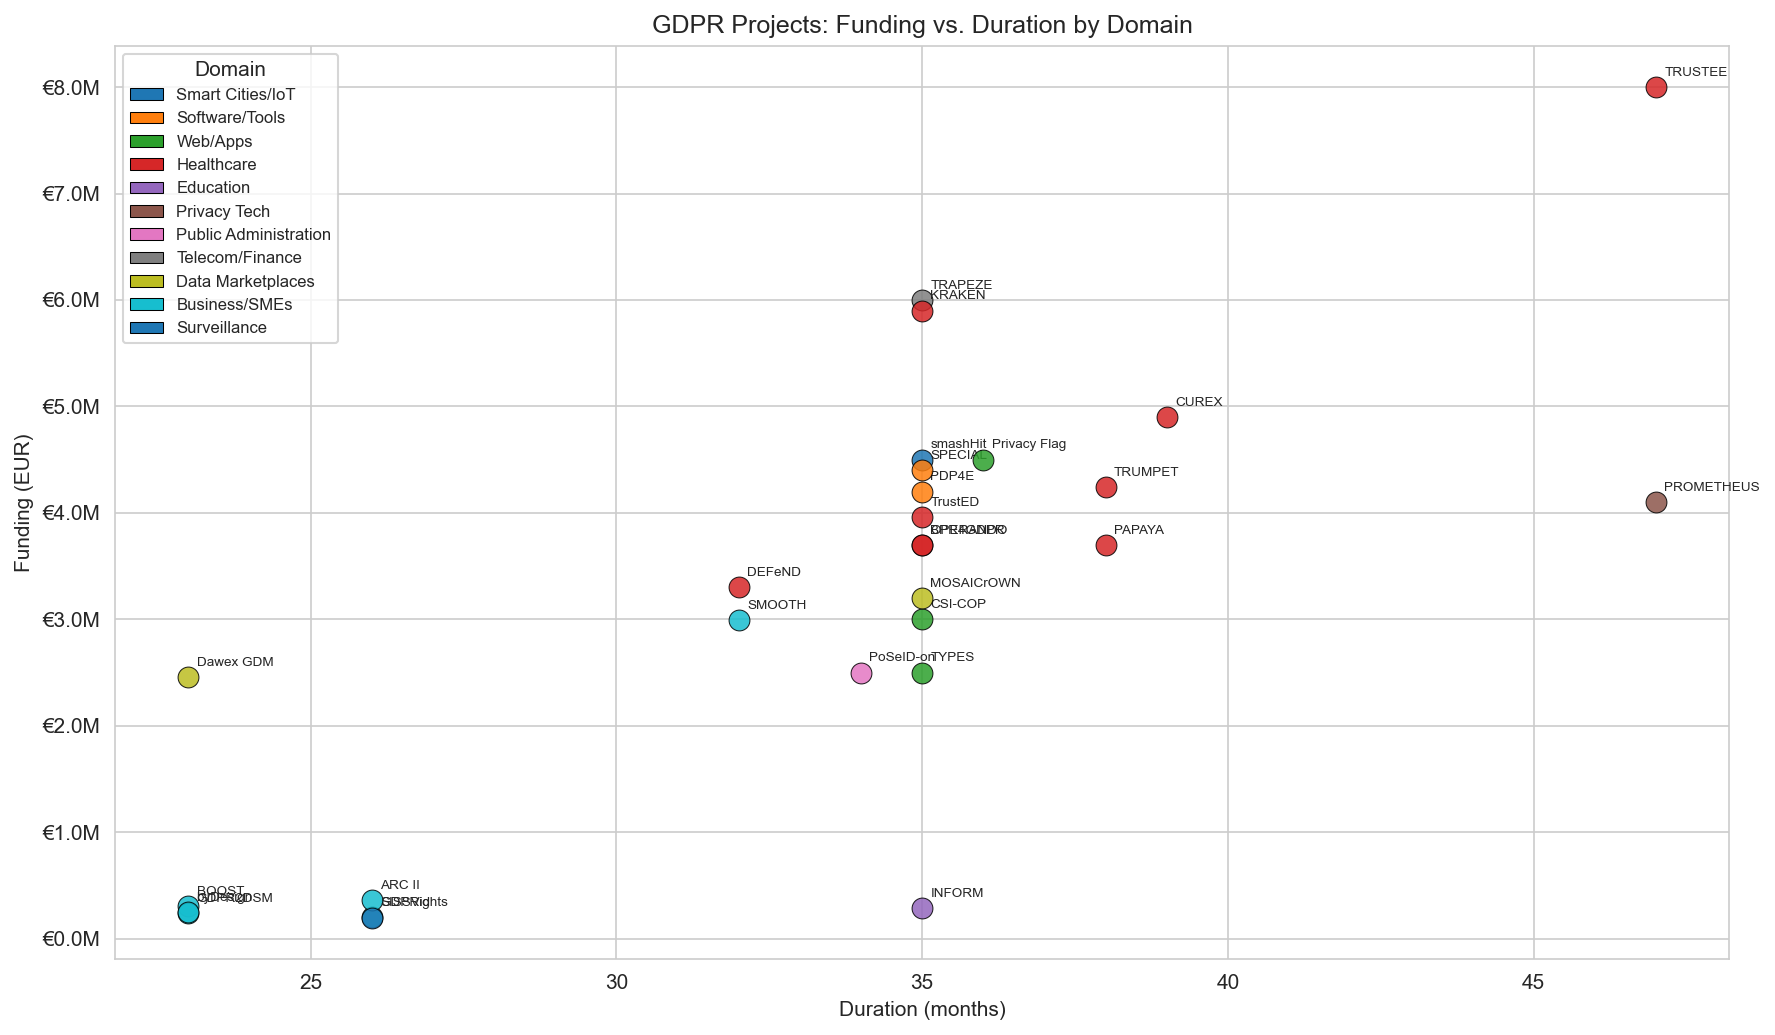

In [22]:
df_funded = df.dropna(subset=['funding_eur'])

fig, ax = plt.subplots(figsize=(12, 7))
domains = df_funded['domain_group'].unique()
palette = sns.color_palette('tab10', len(domains))
color_map = dict(zip(domains, palette))

for _, row in df_funded.iterrows():
    ax.scatter(
        row['duration_months'], row['funding_eur'],
        c=[color_map[row['domain_group']]],
        s=100, edgecolors='black', linewidth=0.5, alpha=0.85, zorder=3
    )
    ax.annotate(row['project_name'],
                (row['duration_months'], row['funding_eur']),
                fontsize=6.5, ha='left', va='bottom', xytext=(4, 4),
                textcoords='offset points')

handles = [Patch(facecolor=color_map[d], label=d, edgecolor='black', linewidth=0.5) for d in domains]
ax.legend(handles=handles, title='Domain', fontsize=8, loc='upper left')
ax.set_xlabel('Duration (months)')
ax.set_ylabel('Funding (EUR)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'€{x/1e6:.1f}M'))
ax.set_title('GDPR Projects: Funding vs. Duration by Domain')
plt.tight_layout()
plt.savefig('funding_vs_duration.png', bbox_inches='tight')
plt.show()

## 2. Funding over Time (start year)

How has per-project funding changed over the years? We plot two separate trend lines here because the dataset contains two distinct populations:

- **Research grants (≥€1M)**: Horizon 2020 and Horizon Europe R&D projects — large multi-partner consortiums
- **Support/training grants (<€1M)**: REC, CERV, and Erasmus+ programmes — focused on SME compliance, awareness campaigns, and training

Lumping these into a single trend line would be misleading — a €200K training grant and an €8M health data space project aren't on the same scale. Splitting them shows whether each funding tier is growing or shrinking independently.

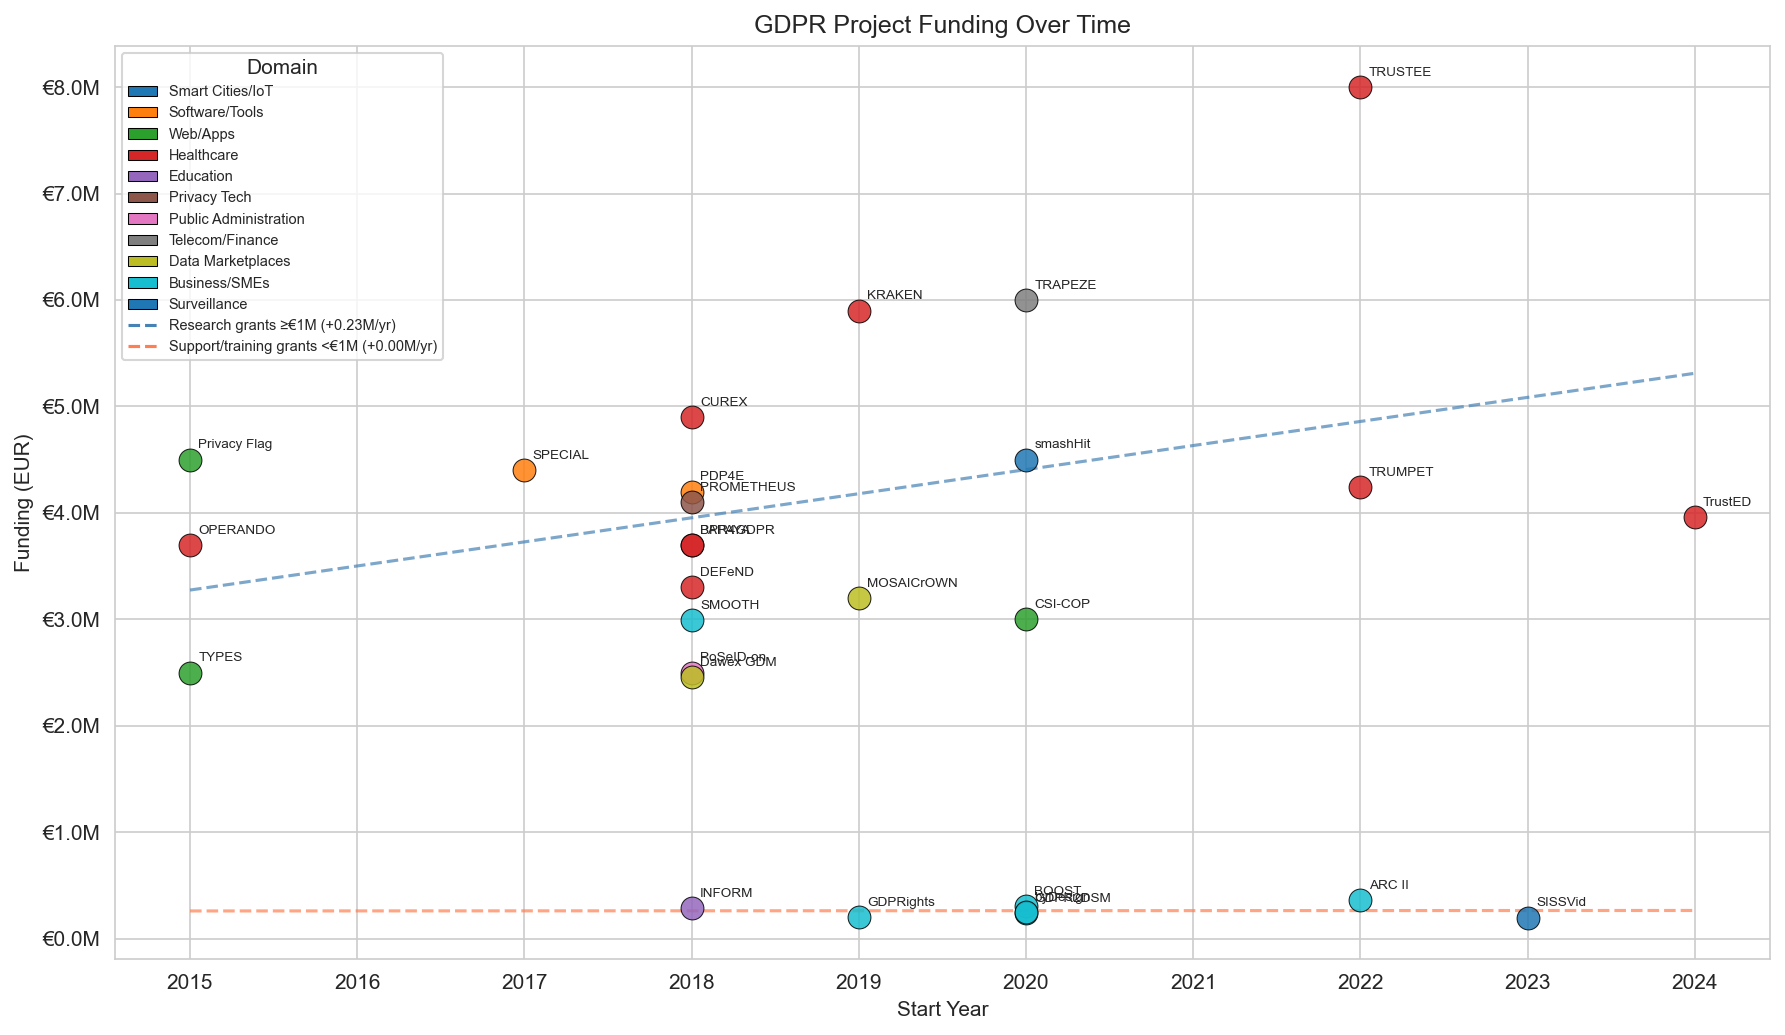

In [23]:
fig, ax = plt.subplots(figsize=(12, 7))

for _, row in df_funded.iterrows():
    ax.scatter(
        row['start_year'], row['funding_eur'],
        c=[color_map[row['domain_group']]],
        s=120, edgecolors='black', linewidth=0.5, alpha=0.85, zorder=3
    )
    ax.annotate(row['project_name'],
                (row['start_year'], row['funding_eur']),
                fontsize=6.5, ha='left', va='bottom', xytext=(4, 4),
                textcoords='offset points')

# Split trend lines at €1M threshold
large = df_funded[df_funded['funding_eur'] >= 1_000_000]
small = df_funded[df_funded['funding_eur'] < 1_000_000]

years_range = np.linspace(df_funded['start_year'].min(), df_funded['start_year'].max(), 50)

if len(large) >= 2:
    z_large = np.polyfit(large['start_year'], large['funding_eur'], 1)
    p_large = np.poly1d(z_large)
    ax.plot(years_range, p_large(years_range), '--', color='steelblue', alpha=0.7)

if len(small) >= 2:
    z_small = np.polyfit(small['start_year'], small['funding_eur'], 1)
    p_small = np.poly1d(z_small)
    ax.plot(years_range, p_small(years_range), '--', color='coral', alpha=0.7)

handles = [Patch(facecolor=color_map[d], label=d, edgecolor='black', linewidth=0.5) for d in domains]
handles.append(plt.Line2D([0], [0], linestyle='--', color='steelblue',
               label=f'Research grants ≥€1M ({z_large[0]/1e6:+.2f}M/yr)'))
if len(small) >= 2:
    handles.append(plt.Line2D([0], [0], linestyle='--', color='coral',
                   label=f'Support/training grants <€1M ({z_small[0]/1e6:+.2f}M/yr)'))
ax.legend(handles=handles, title='Domain', fontsize=7, loc='upper left')
ax.set_xlabel('Start Year')
ax.set_ylabel('Funding (EUR)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'€{x/1e6:.1f}M'))
ax.set_title('GDPR Project Funding Over Time')
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig('funding_over_time.png', bbox_inches='tight')
plt.show()

## 3. Domain × Year Heatmap (total funding)

Which domains got the most money, and when? This heatmap sums up all project funding per domain per start year. Dark cells mean heavy investment. Healthcare stands out in 2018 and 2022, while Business/SME funding is spread across more years but in smaller amounts.

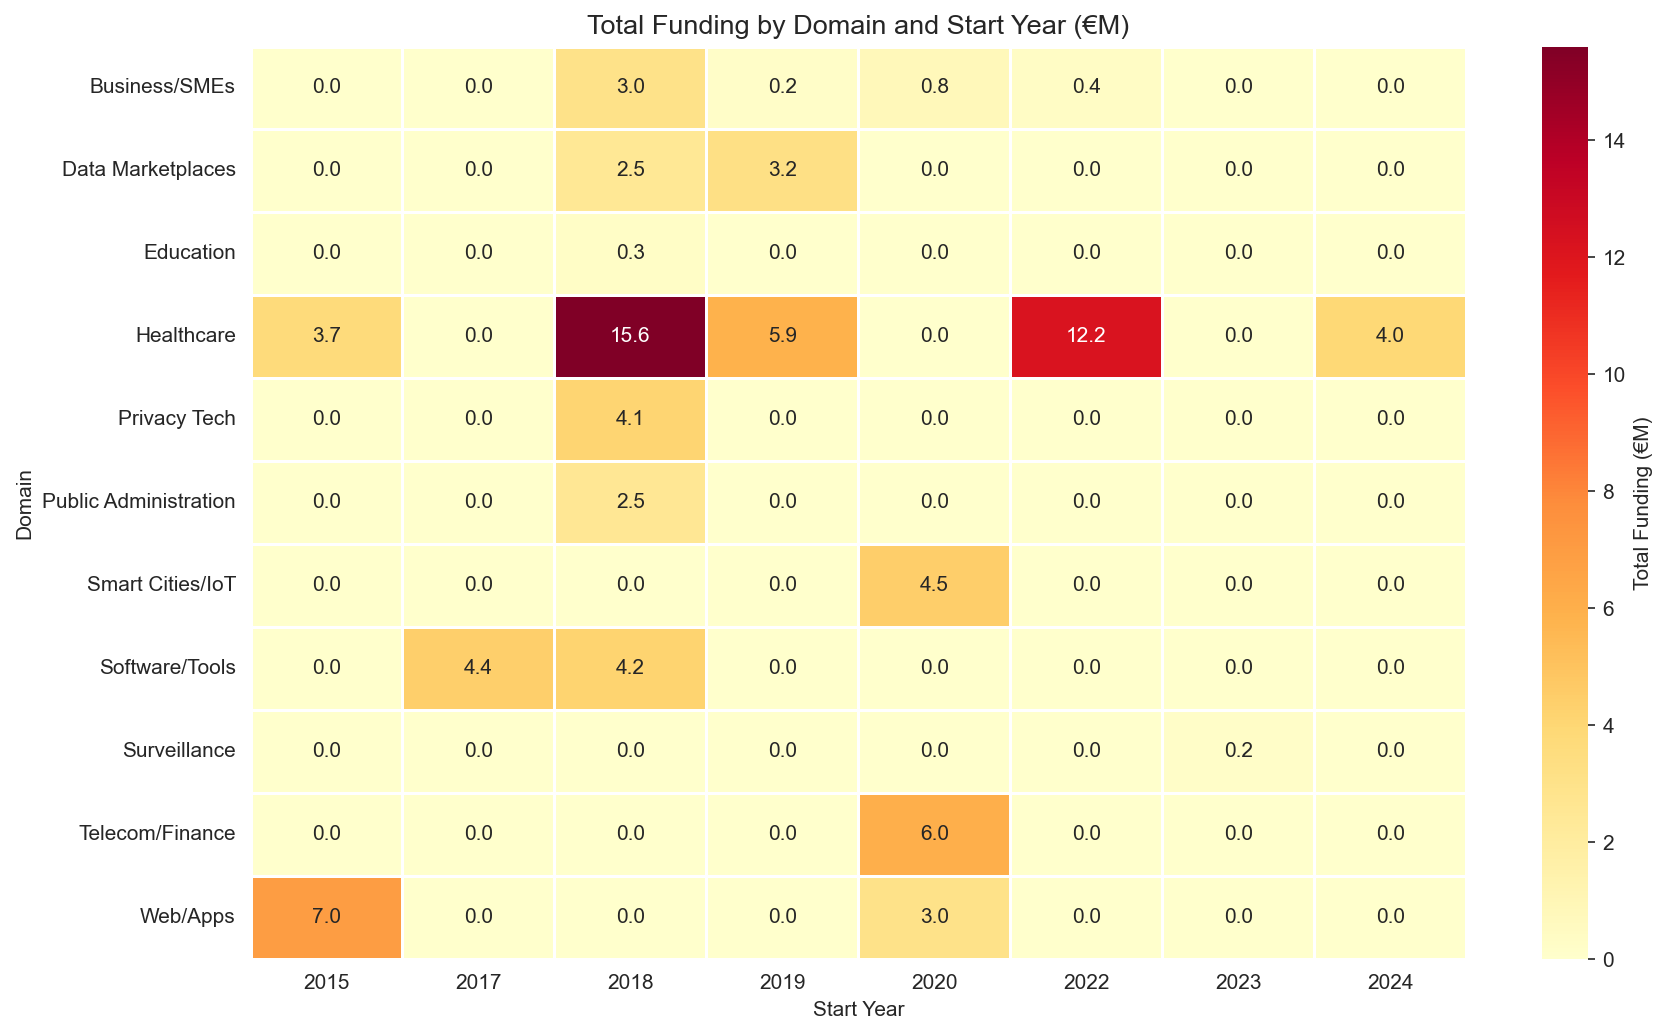

In [24]:
pivot = df.pivot_table(
    index='domain_group',
    columns='start_year',
    values='funding_eur',
    aggfunc='sum',
    fill_value=0
)

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    pivot / 1e6,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Total Funding (€M)'}
)
ax.set_title('Total Funding by Domain and Start Year (€M)', fontsize=13)
ax.set_xlabel('Start Year')
ax.set_ylabel('Domain')
plt.tight_layout()
plt.savefig('domain_year_heatmap.png', bbox_inches='tight')
plt.show()

## 4. Domain × Year Heatmap (project count)

Same breakdown, but counting projects instead of summing funding. This helps separate "one expensive project" from "many smaller projects." For instance, 2018 has the most projects overall, but the per-project funding that year was lower than 2022 — a classic early-response pattern where many small initiatives launched right after GDPR enforcement.

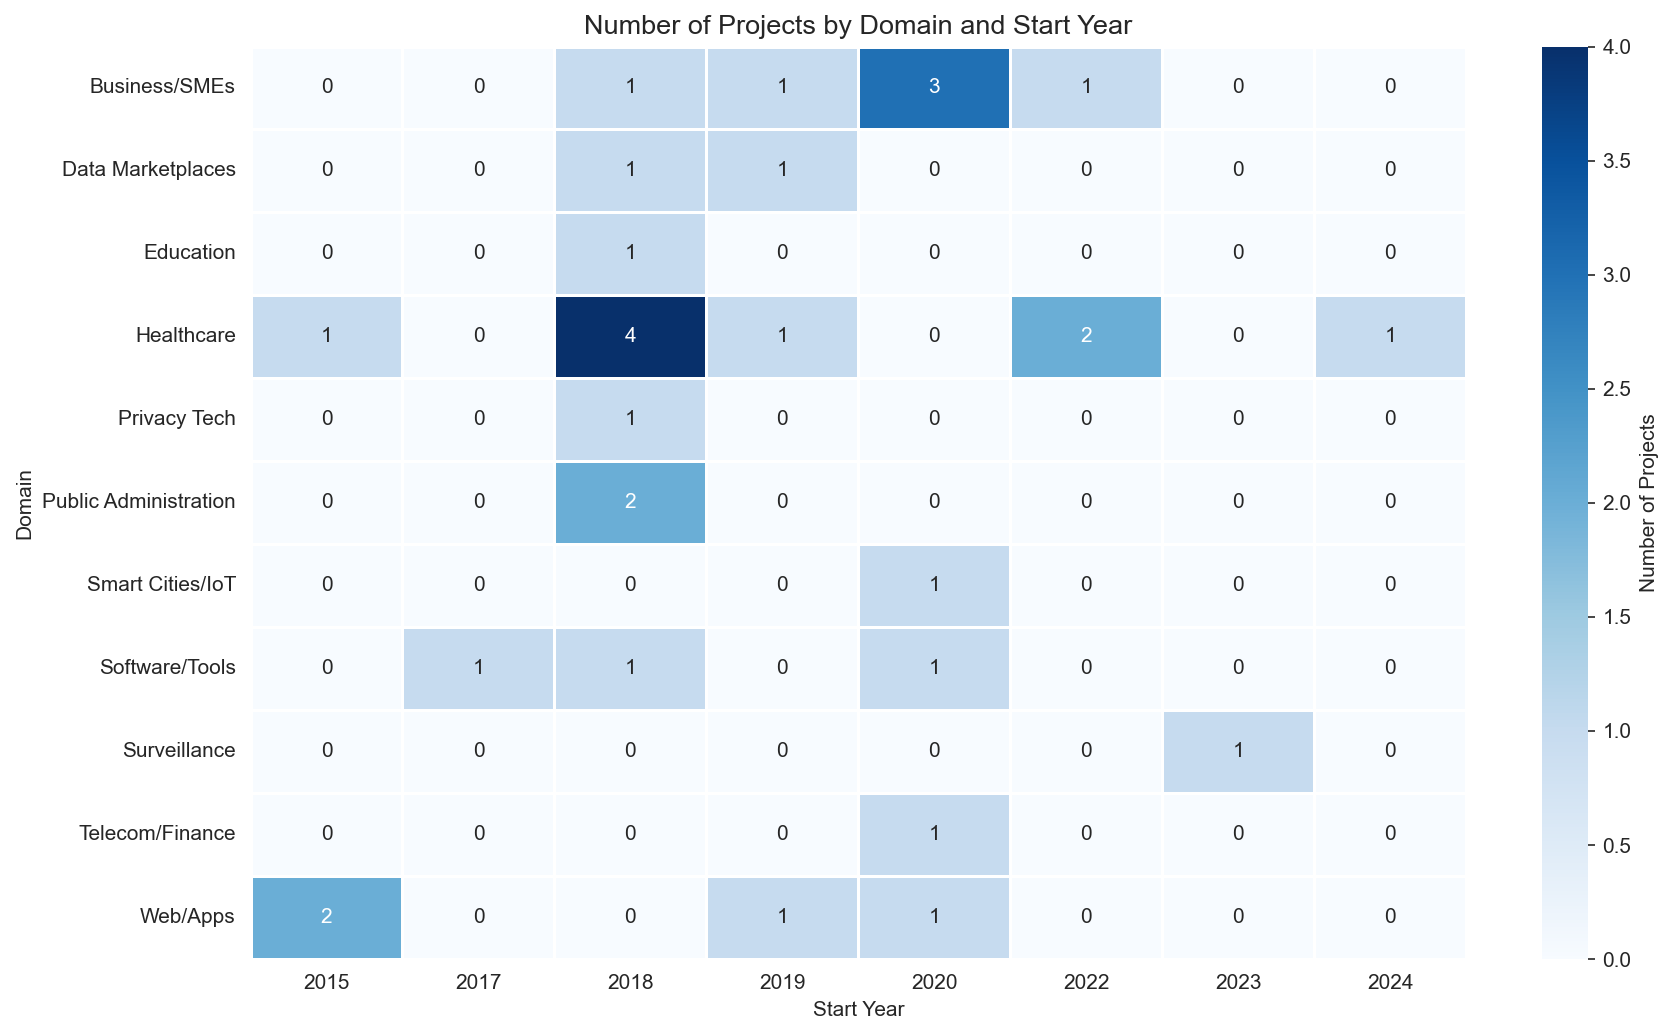

In [25]:
pivot_count = df.pivot_table(
    index='domain_group',
    columns='start_year',
    values='project_name',
    aggfunc='count',
    fill_value=0
)

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    pivot_count,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Number of Projects'}
)
ax.set_title('Number of Projects by Domain and Start Year', fontsize=13)
ax.set_xlabel('Start Year')
ax.set_ylabel('Domain')
plt.tight_layout()
plt.savefig('domain_year_count_heatmap.png', bbox_inches='tight')
plt.show()

## 5. Correlation: Funding vs. Consortium Size vs. Duration

We check whether funding, consortium size (number of partner organizations), and project duration are related. Consortium size data comes from CORDIS project pages — only 19 out of 31 projects have it, so take the correlations with that caveat.

The Pearson correlation coefficient (r) is shown in each subplot title. Values close to 1 mean a strong positive relationship; close to 0 means no linear relationship.

Projects with both funding and consortium size: 19


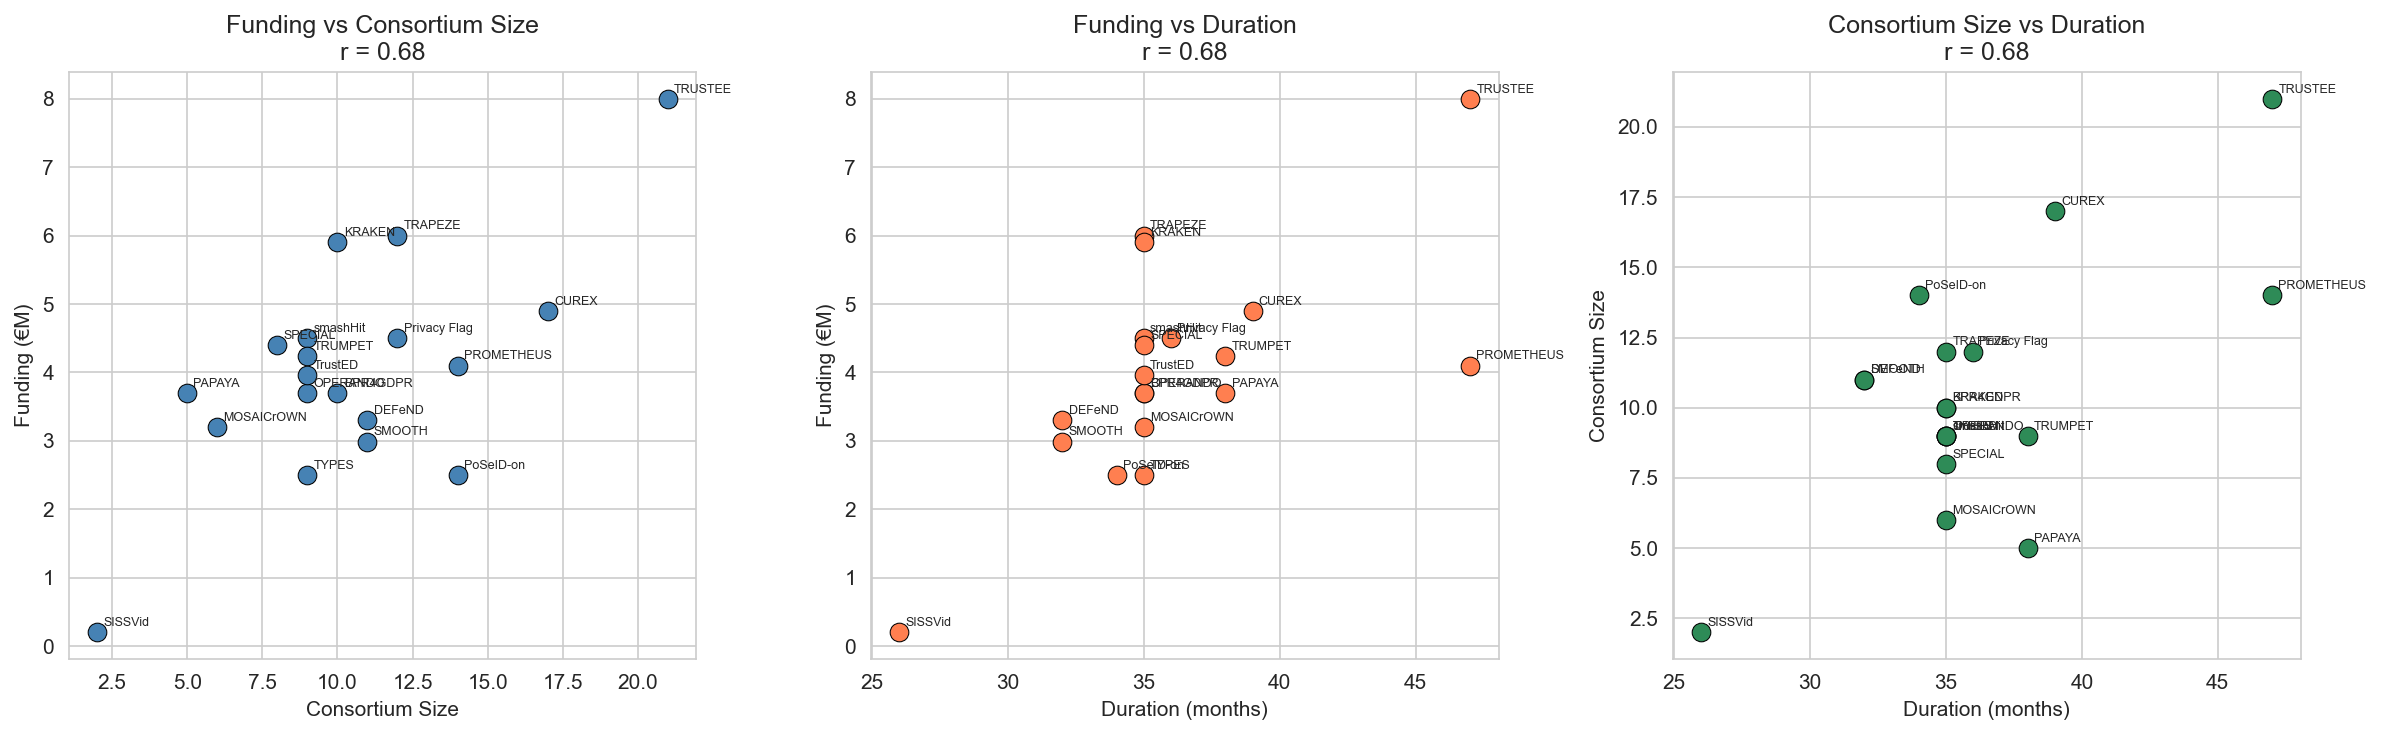

In [ ]:
df_corr = df.dropna(subset=['funding_eur', 'consortium_size'])
print(f'Projects with both funding and consortium size: {len(df_corr)}')

if len(df_corr) >= 5:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    # Funding vs Consortium Size
    axes[0].scatter(df_corr['consortium_size'], df_corr['funding_eur'] / 1e6, 
                    c='steelblue', s=80, edgecolors='black', linewidth=0.5)
    for _, r in df_corr.iterrows():
        axes[0].annotate(r['project_name'], (r['consortium_size'], r['funding_eur']/1e6),
                         fontsize=6, xytext=(3, 3), textcoords='offset points')
    corr1 = df_corr['consortium_size'].corr(df_corr['funding_eur'])
    axes[0].set_xlabel('Consortium Size')
    axes[0].set_ylabel('Funding (€M)')
    axes[0].set_title(f'Funding vs Consortium Size\nr = {corr1:.2f}')
    
    # Funding vs Duration
    axes[1].scatter(df_corr['duration_months'], df_corr['funding_eur'] / 1e6,
                    c='coral', s=80, edgecolors='black', linewidth=0.5)
    for _, r in df_corr.iterrows():
        axes[1].annotate(r['project_name'], (r['duration_months'], r['funding_eur']/1e6),
                         fontsize=6, xytext=(3, 3), textcoords='offset points')
    corr2 = df_corr['duration_months'].corr(df_corr['funding_eur'])
    axes[1].set_xlabel('Duration (months)')
    axes[1].set_ylabel('Funding (€M)')
    axes[1].set_title(f'Funding vs Duration\nr = {corr2:.2f}')
    
    # Consortium Size vs Duration
    axes[2].scatter(df_corr['duration_months'], df_corr['consortium_size'],
                    c='seagreen', s=80, edgecolors='black', linewidth=0.5)
    for _, r in df_corr.iterrows():
        axes[2].annotate(r['project_name'], (r['duration_months'], r['consortium_size']),
                         fontsize=6, xytext=(3, 3), textcoords='offset points')
    corr3 = df_corr['duration_months'].corr(df_corr['consortium_size'])
    axes[2].set_xlabel('Duration (months)')
    axes[2].set_ylabel('Consortium Size')
    axes[2].set_title(f'Consortium Size vs Duration\nr = {corr3:.2f}')
    
    plt.tight_layout()
    plt.savefig('correlation_plots.png', bbox_inches='tight')
    plt.show()
else:
    print('Not enough data points with both fields — skip correlation plots.')

## 6. Gantt-style Timeline

A timeline view of all 31 projects, sorted by start date and colored by domain. The red dashed line marks GDPR enforcement (May 25, 2018). This makes it easy to see which projects were pre-GDPR (anticipatory) vs. post-GDPR (reactive), and how different domains entered the space at different times.

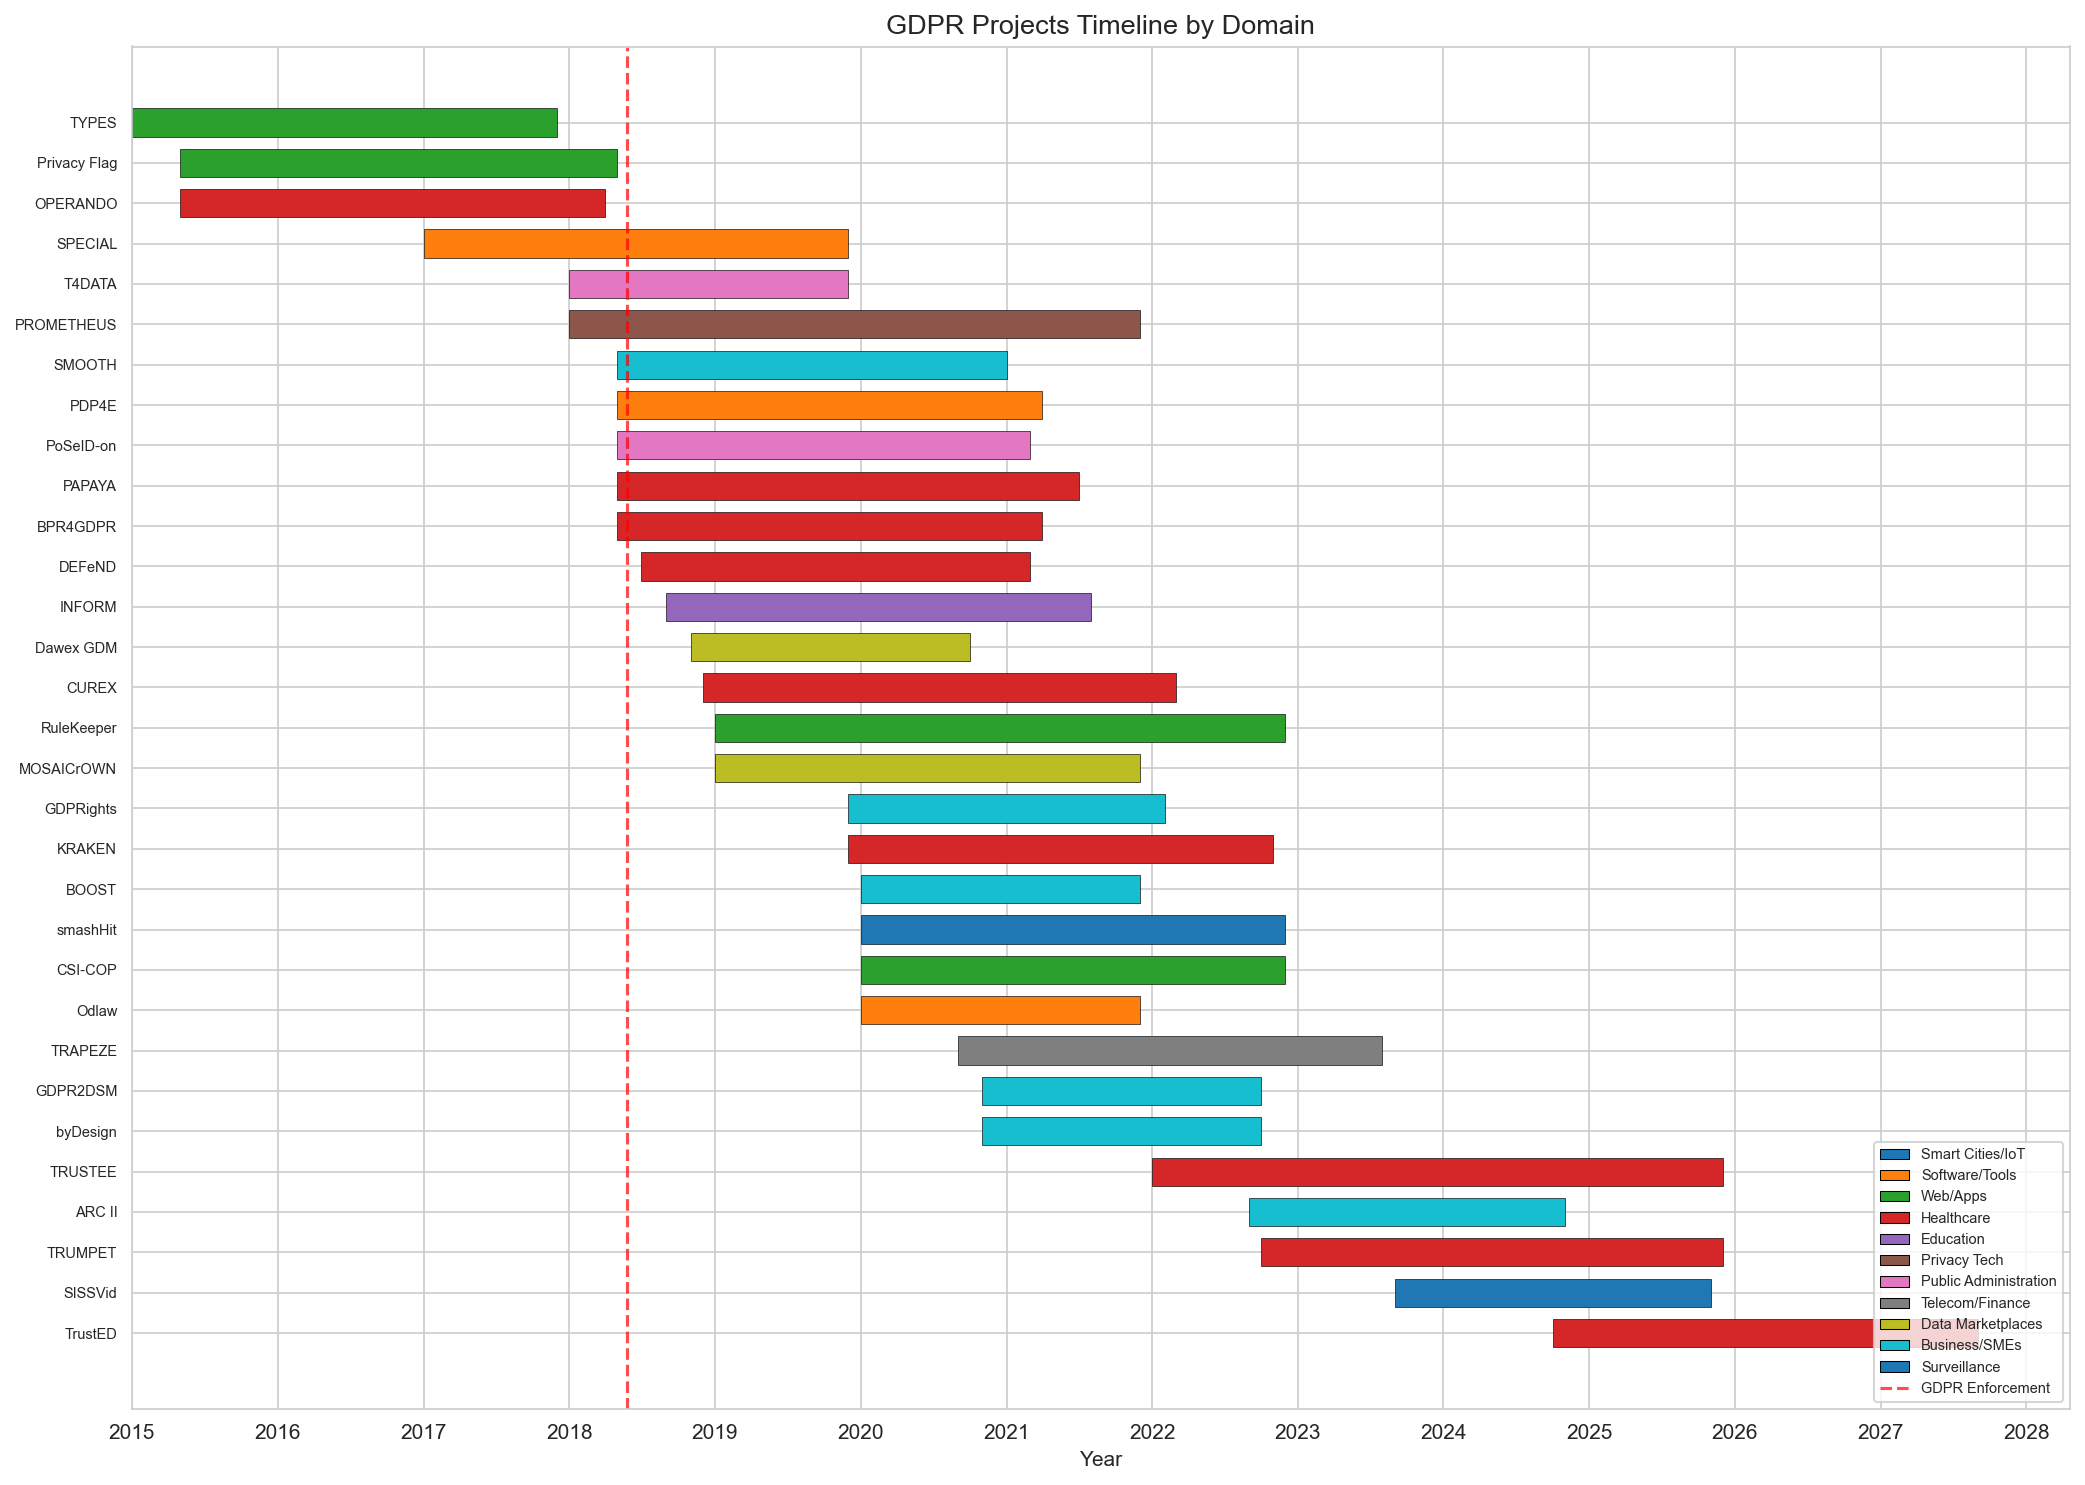

In [27]:
import matplotlib.dates as mdates

df_sorted = df.sort_values('start_date')

fig, ax = plt.subplots(figsize=(14, 10))
yticks = []
for i, (_, row) in enumerate(df_sorted.iterrows()):
    color = color_map.get(row['domain_group'], 'gray')
    start = row['start_date']
    duration = row['end_date'] - row['start_date']
    ax.barh(i, duration, left=start, color=color, edgecolor='black', linewidth=0.3, height=0.7)
    yticks.append(row['project_name'])

ax.set_yticks(range(len(yticks)))
ax.set_yticklabels(yticks, fontsize=7)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_xlabel('Year')
ax.set_title('GDPR Projects Timeline by Domain', fontsize=13)

# GDPR enforcement line
ax.axvline(pd.Timestamp('2018-05-25'), color='red', linestyle='--', alpha=0.7, label='GDPR Enforcement (May 2018)')

handles = [Patch(facecolor=color_map[d], label=d, edgecolor='black', linewidth=0.5) for d in color_map]
handles.append(plt.Line2D([0], [0], linestyle='--', color='red', alpha=0.7, label='GDPR Enforcement'))
ax.legend(handles=handles, fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig('project_timeline.png', bbox_inches='tight')
plt.show()